In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("Telco_Customer_Churn_Dataset  (3).csv")

In [3]:
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## Data Cleaning

In [6]:
df_clean = df.copy()
print("Original shape:", df_clean.shape)

Original shape: (7043, 21)


In [7]:
# 1. Standardize column names
df_clean.columns = (
    df_clean.columns
    .str.strip().str.lower()
    .str.replace(r"[^\w\s]", "", regex=True)
    .str.replace(r"\s+", "_", regex=True)
)

In [8]:
# 2. FIX: trim whitespace FIRST, then convert placeholders to NaN
#    (so a blank " " becomes "" and is caught)
text_cols = df_clean.select_dtypes(include=["object", "str"]).columns
for col in text_cols:
    df_clean[col] = df_clean[col].str.strip()
df_clean = df_clean.replace(["?", "N/A", "n/a", "NA", "-", "", "null", "None"], np.nan)


In [9]:
# 3. FIX: convert totalcharges to numeric BEFORE the generic fill step
df_clean["totalcharges"] = pd.to_numeric(df_clean["totalcharges"], errors="coerce")

blank = df_clean["totalcharges"].isnull()
print("Blank totalcharges:", blank.sum())                      # 11
print("All have tenure 0:", (df_clean.loc[blank, "tenure"] == 0).all())  # True
df_clean.loc[blank, "totalcharges"] = 0 

Blank totalcharges: 11
All have tenure 0: True


In [10]:
# 4. Duplicates (full rows, and by customer ID)
print("Duplicate rows:", df_clean.duplicated().sum())
print("customerid unique:", df_clean["customerid"].is_unique)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

Duplicate rows: 0
customerid unique: True


In [11]:
# 5. Remaining missing values
mostly_empty = df_clean.columns[df_clean.isnull().mean() > 0.5]
df_clean = df_clean.drop(columns=mostly_empty)
print("Dropped columns:", list(mostly_empty))

for col in df_clean.select_dtypes(include=np.number).columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in df_clean.select_dtypes(include=["object", "str", "category"]).columns:
    if df_clean[col].notna().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])


Dropped columns: []


In [12]:
# 6. FIX: check text columns for inconsistent spellings
for col in df_clean.select_dtypes(include=["object", "str"]).columns:
    if col != "customerid":
        print(f"{col}: {sorted(df_clean[col].unique())}")

gender: ['Female', 'Male']
partner: ['No', 'Yes']
dependents: ['No', 'Yes']
phoneservice: ['No', 'Yes']
multiplelines: ['No', 'No phone service', 'Yes']
internetservice: ['DSL', 'Fiber optic', 'No']
onlinesecurity: ['No', 'No internet service', 'Yes']
onlinebackup: ['No', 'No internet service', 'Yes']
deviceprotection: ['No', 'No internet service', 'Yes']
techsupport: ['No', 'No internet service', 'Yes']
streamingtv: ['No', 'No internet service', 'Yes']
streamingmovies: ['No', 'No internet service', 'Yes']
contract: ['Month-to-month', 'One year', 'Two year']
paperlessbilling: ['No', 'Yes']
paymentmethod: ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
churn: ['No', 'Yes']


In [13]:
# 7. FIX: encode churn, then show the class counts directly
df_clean["churn"] = df_clean["churn"].map({"Yes": 1, "No": 0})
print("\nChurn counts:\n", df_clean["churn"].value_counts())
print("\nChurn %:\n", (df_clean["churn"].value_counts(normalize=True) * 100).round(1))


Churn counts:
 churn
0    5174
1    1869
Name: count, dtype: int64

Churn %:
 churn
0    73.5
1    26.5
Name: proportion, dtype: float64


In [14]:
# 8. Final verification
print("\nMissing:", df_clean.isnull().sum().sum())
print("Duplicates:", df_clean.duplicated().sum())
print("Shape:", df_clean.shape)
df_clean.info()


Missing: 0
Duplicates: 0
Shape: (7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerid        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   seniorcitizen     7043 non-null   int64  
 3   partner           7043 non-null   str    
 4   dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   phoneservice      7043 non-null   str    
 7   multiplelines     7043 non-null   str    
 8   internetservice   7043 non-null   str    
 9   onlinesecurity    7043 non-null   str    
 10  onlinebackup      7043 non-null   str    
 11  deviceprotection  7043 non-null   str    
 12  techsupport       7043 non-null   str    
 13  streamingtv       7043 non-null   str    
 14  streamingmovies   7043 non-null   str    
 15  contract          7043 non-null   str    
 16  paperless

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.


In [20]:
sns.set_theme(style="whitegrid")
num_cols = ["tenure", "monthlycharges", "totalcharges"]
summary = pd.DataFrame({
    "mean":   df_clean[num_cols].mean(),
    "median": df_clean[num_cols].median(),
    "mode":   df_clean[num_cols].mode().iloc[0],
    "std":    df_clean[num_cols].std(),
    "min":    df_clean[num_cols].min(),
    "max":    df_clean[num_cols].max(),
}).round(2)
summary

,mean,median,mode,std,min,max
tenure,32.37,29.00,1.00,24.56,0.00,72.00
monthlycharges,64.76,70.35,20.05,30.09,18.25,118.75
totalcharges,2279.73,1394.55,0.00,2266.79,0.00,8684.80


In [21]:
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
seniorcitizen,7043.0,0.162147,0.368612,0.00,0.00,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
monthlycharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
totalcharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80
churn,7043.0,0.265370,0.441561,0.00,0.00,0.00,1.00,1.00


In [22]:
cat_cols = df_clean.select_dtypes(include=["object", "str"]).columns.drop("customerid")
df_clean[cat_cols].mode().iloc[0]

gender                          Male
partner                           No
dependents                        No
phoneservice                     Yes
multiplelines                     No
internetservice          Fiber optic
onlinesecurity                    No
onlinebackup                      No
deviceprotection                  No
techsupport                       No
streamingtv                       No
streamingmovies                   No
contract              Month-to-month
paperlessbilling                 Yes
paymentmethod       Electronic check
Name: 0, dtype: str

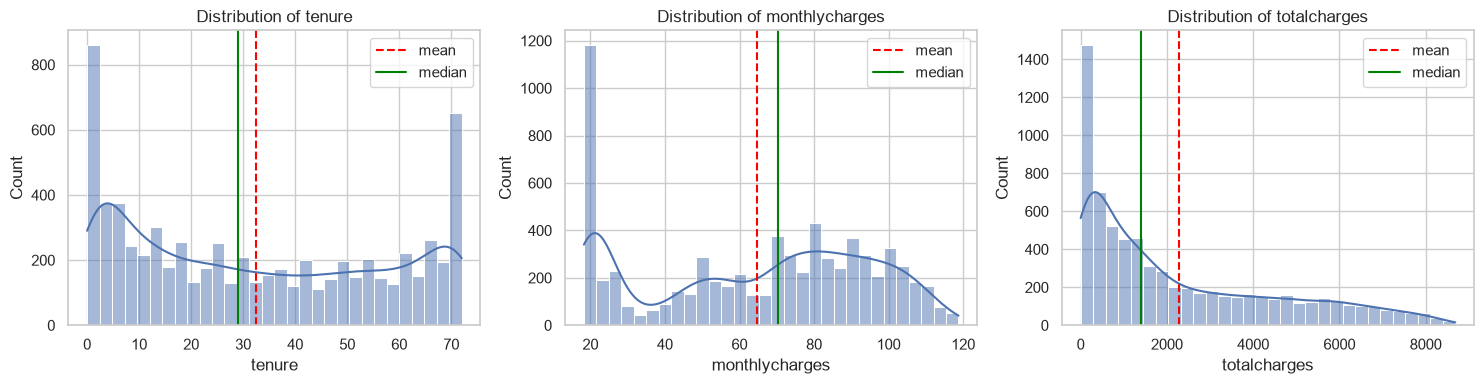

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df_clean[col], bins=30, kde=True, ax=ax)
    ax.axvline(df_clean[col].mean(), color="red", linestyle="--", label="mean")
    ax.axvline(df_clean[col].median(), color="green", linestyle="-", label="median")
    ax.set_title(f"Distribution of {col}")
    ax.legend()
plt.tight_layout()
plt.show()

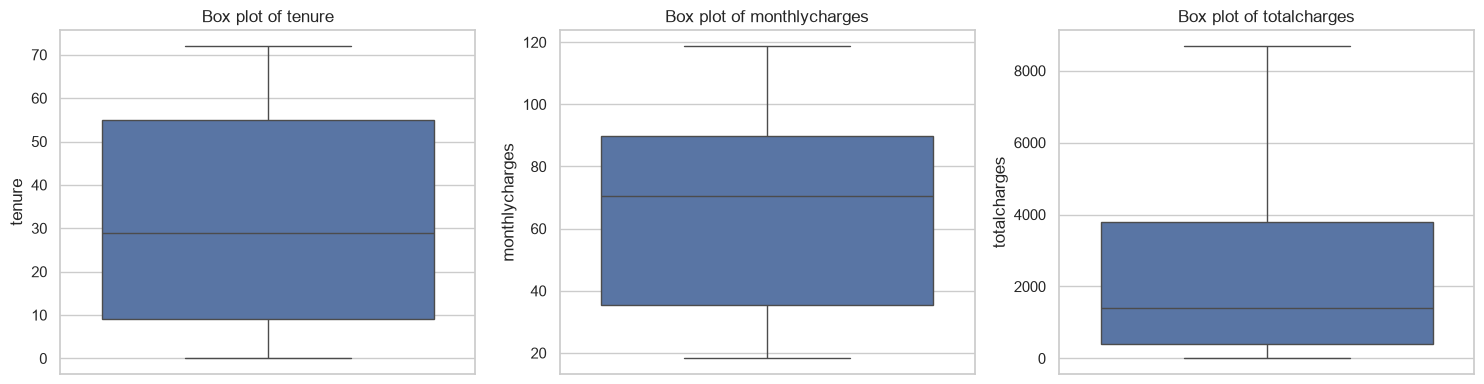

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df_clean[col], ax=ax)
    ax.set_title(f"Box plot of {col}")
plt.tight_layout()
plt.show()

C:\Users\User\AppData\Local\Temp\ipykernel_6344\3428050619.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Stayed (0)", "Churned (1)"])
C:\Users\User\AppData\Local\Temp\ipykernel_6344\3428050619.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Stayed (0)", "Churned (1)"])
C:\Users\User\AppData\Local\Temp\ipykernel_6344\3428050619.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Stayed (0)", "Churned (1)"])


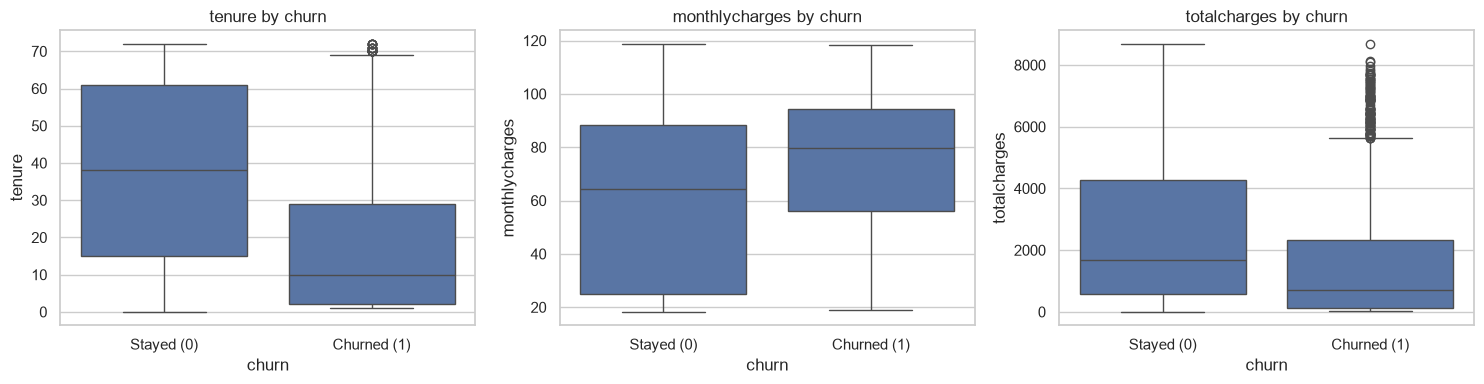

,tenure,monthlycharges,totalcharges
churn,,,
0,38.0,64.43,1679.52
1,10.0,79.65,703.55


In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x="churn", y=col, data=df_clean, ax=ax)
    ax.set_xticklabels(["Stayed (0)", "Churned (1)"])
    ax.set_title(f"{col} by churn")
plt.tight_layout()
plt.show()

df_clean.groupby("churn")[num_cols].median().round(2)

         customers  percent
churn                      
Stayed        5174     73.5
Churned       1869     26.5


C:\Users\User\AppData\Local\Temp\ipykernel_6344\397337598.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(["Stayed", "Churned"])


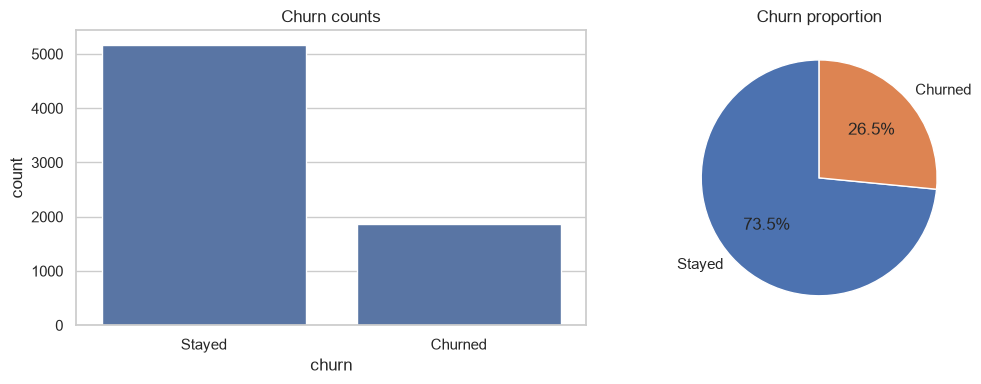

In [26]:
counts = df_clean["churn"].value_counts().rename({0: "Stayed", 1: "Churned"})
percent = (df_clean["churn"].value_counts(normalize=True) * 100).round(1).rename({0: "Stayed", 1: "Churned"})
print(pd.DataFrame({"customers": counts, "percent": percent}))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="churn", data=df_clean, ax=axes[0])
axes[0].set_xticklabels(["Stayed", "Churned"])
axes[0].set_title("Churn counts")
axes[1].pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90)
axes[1].set_title("Churn proportion")
plt.tight_layout()
plt.show()

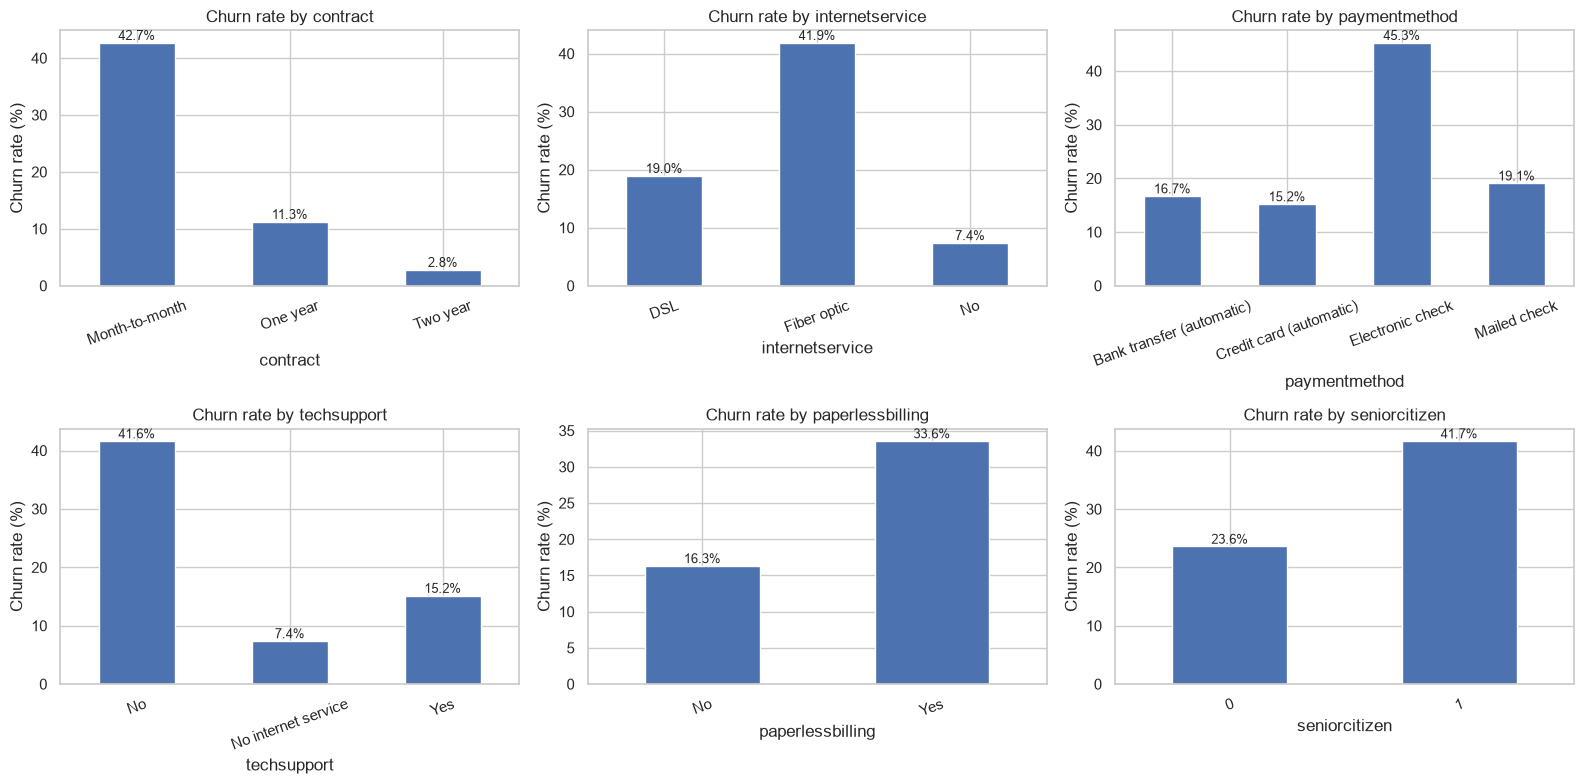

In [27]:
cols = ["contract", "internetservice", "paymentmethod", "techsupport", "paperlessbilling", "seniorcitizen"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, cols):
    rate = df_clean.groupby(col)["churn"].mean() * 100
    rate.plot(kind="bar", ax=ax, rot=20)
    ax.set_ylabel("Churn rate (%)")
    ax.set_title(f"Churn rate by {col}")
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width()/2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

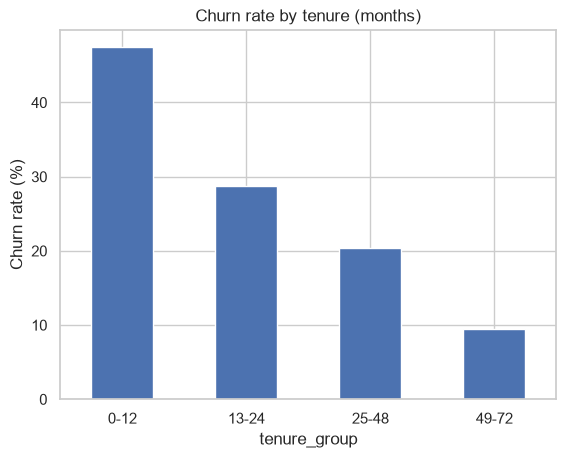

tenure_group
0-12     47.4
13-24    28.7
25-48    20.4
49-72     9.5
Name: churn, dtype: float64

In [28]:
df_clean["tenure_group"] = pd.cut(df_clean["tenure"], bins=[-1, 12, 24, 48, 72],
                                  labels=["0-12", "13-24", "25-48", "49-72"])
rate = df_clean.groupby("tenure_group", observed=True)["churn"].mean() * 100
rate.plot(kind="bar", rot=0, title="Churn rate by tenure (months)")
plt.ylabel("Churn rate (%)")
plt.show()
rate.round(1)

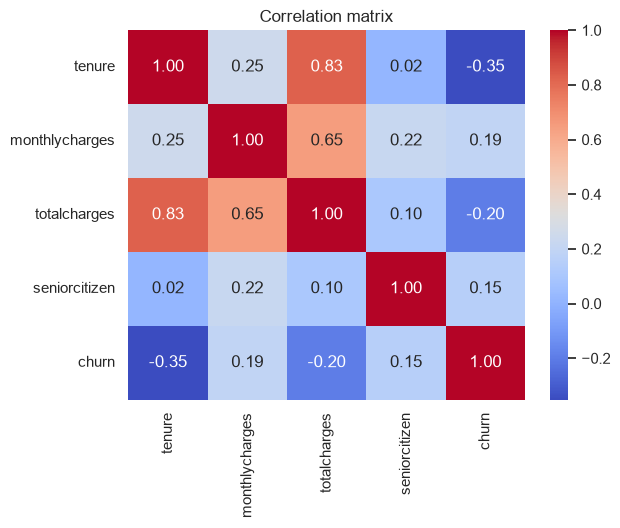

In [29]:
sns.heatmap(df_clean[num_cols + ["seniorcitizen", "churn"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation matrix")
plt.show()

In [30]:
sns.set_theme(style="whitegrid")

df_clean["tenure_segment"] = pd.cut(
    df_clean["tenure"],
    bins=[-1, 12, 36, 72],
    labels=["0-12 months", "13-36 months", "37+ months"]
)

seg_counts = df_clean["tenure_segment"].value_counts().sort_index()
seg_pct = (seg_counts / seg_counts.sum() * 100).round(1)
print(pd.DataFrame({"customers": seg_counts, "percent": seg_pct}))

                customers  percent
tenure_segment                    
0-12 months          2186     31.0
13-36 months         1856     26.4
37+ months           3001     42.6


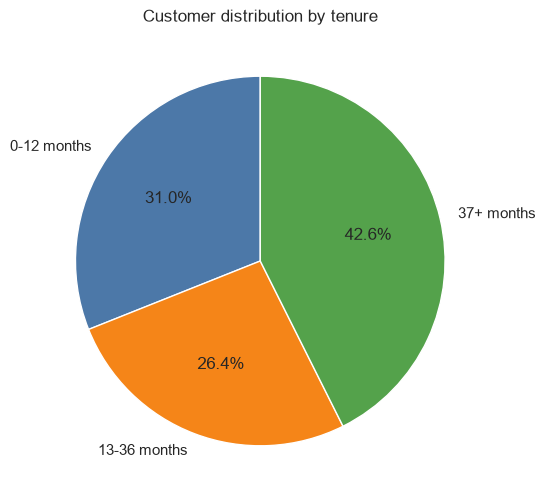

In [31]:
colors = ["#4C78A8", "#F58518", "#54A24B"]
plt.figure(figsize=(6, 6))
plt.pie(seg_counts, labels=seg_counts.index, autopct="%1.1f%%", startangle=90,
        colors=colors, wedgeprops={"edgecolor": "white"})
plt.title("Customer distribution by tenure")
plt.show()

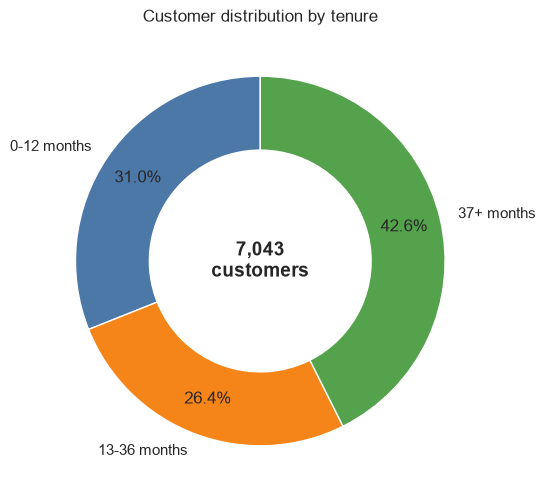

In [32]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(seg_counts, labels=seg_counts.index, autopct="%1.1f%%", startangle=90,
       colors=colors, pctdistance=0.8,
       wedgeprops={"width": 0.4, "edgecolor": "white"})
ax.text(0, 0, f"{seg_counts.sum():,}\ncustomers", ha="center", va="center",
        fontsize=14, fontweight="bold")
ax.set_title("Customer distribution by tenure")
plt.show()

In [34]:
avg = (df_clean.groupby(["tenure_segment", "churn"], observed=True)["monthlycharges"]
       .mean().round(2).unstack())
avg.columns = ["Stayed", "Churned"]
print(avg)

                Stayed  Churned
tenure_segment                 
0-12 months      46.71    66.49
13-36 months     57.26    80.70
37+ months       69.68    89.18


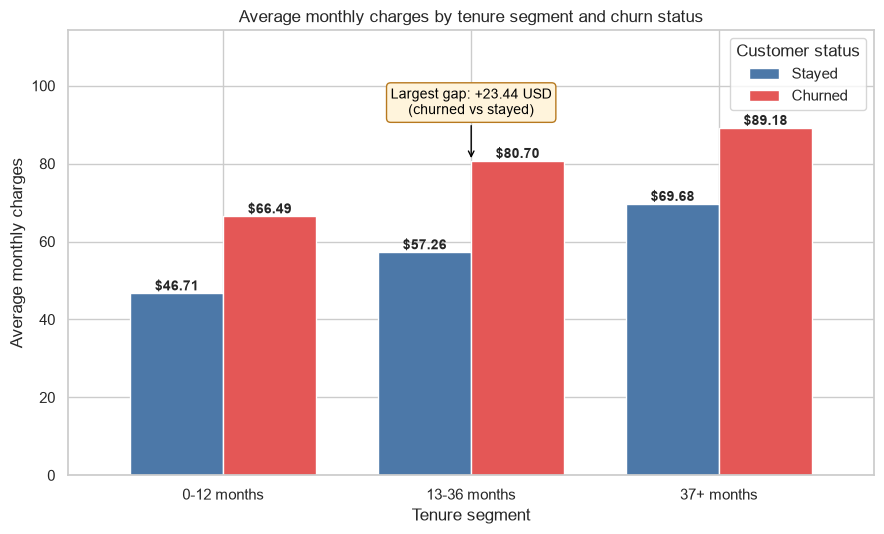

In [35]:
fig, ax = plt.subplots(figsize=(9, 5.5))
avg.plot(kind="bar", ax=ax, color=["#4C78A8", "#E45756"], width=0.75, rot=0)

# value labels on every bar
for p in ax.patches:
    ax.annotate(f"${p.get_height():.2f}",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=10, fontweight="bold")

# highlight the biggest gap between churned and stayed
gap = (avg["Churned"] - avg["Stayed"])
biggest = gap.abs().idxmax()
pos = list(avg.index).index(biggest)
top = avg.loc[biggest].max()
ax.annotate(f"Largest gap: {gap[biggest]:+.2f} USD\n(churned vs stayed)",
            xy=(pos, top), xytext=(pos, top + 12),
            ha="center", fontsize=10, color="black",
            arrowprops=dict(arrowstyle="->", color="black"),
            bbox=dict(boxstyle="round", fc="#FFF4DC", ec="#B7791F"))

ax.set_ylim(0, avg.values.max() + 25)
ax.set_ylabel("Average monthly charges")
ax.set_xlabel("Tenure segment")
ax.set_title("Average monthly charges by tenure segment and churn status")
ax.legend(title="Customer status")
plt.tight_layout()
plt.show()

In [36]:
overall = df_clean.groupby("tenure_segment", observed=True)["monthlycharges"].mean().round(2)
print(overall)

tenure_segment
0-12 months     56.10
13-36 months    63.25
37+ months      72.01
Name: monthlycharges, dtype: float64


In [37]:
churn_rate = (df_clean.groupby("tenure_segment", observed=True)["churn"].mean() * 100).round(1)
print(churn_rate)

tenure_segment
0-12 months     47.4
13-36 months    25.5
37+ months      11.9
Name: churn, dtype: float64


In [38]:
df_clean["tenure_segment"] = pd.cut(df_clean["tenure"], bins=[-1, 12, 36, 72],
                                    labels=["0-12 months", "13-36 months", "37+ months"])

In [39]:
tenure_stats = df_clean.groupby("tenure_segment", observed=True).agg(
    customers=("churn", "size"),
    churn_rate_pct=("churn", lambda s: round(s.mean() * 100, 1)),
    avg_monthly=("monthlycharges", "mean"),
    median_monthly=("monthlycharges", "median"),
    avg_total=("totalcharges", "mean"),
    median_total=("totalcharges", "median"),
    std_monthly=("monthlycharges", "std"),
).round(2)
tenure_stats

,customers,churn_rate_pct,avg_monthly,median_monthly,avg_total,median_total,std_monthly
tenure_segment,,,,,,,
0-12 months,2186,47.4,56.10,55.90,275.23,170.88,26.53
13-36 months,1856,25.5,63.25,69.68,1513.54,1404.98,28.82
37+ months,3001,11.9,72.01,80.30,4213.72,4282.40,31.47


In [40]:
def churn_by(col, order=None):
    t = df_clean.groupby(col, observed=True)["churn"].agg(customers="size", churned="sum", rate="mean")
    t["churn_rate_pct"] = (t["rate"] * 100).round(1)
    t = t.drop(columns="rate")
    return t.sort_values("churn_rate_pct", ascending=False)

In [41]:
df_clean["senior_label"] = df_clean["seniorcitizen"].map({0: "Not senior", 1: "Senior"})

for col in ["gender", "senior_label", "partner", "dependents"]:
    print(f"\n--- Churn by {col} ---")
    print(churn_by(col))


--- Churn by gender ---
        customers  churned  churn_rate_pct
gender                                    
Female       3488      939            26.9
Male         3555      930            26.2

--- Churn by senior_label ---
              customers  churned  churn_rate_pct
senior_label                                    
Senior             1142      476            41.7
Not senior         5901     1393            23.6

--- Churn by partner ---
         customers  churned  churn_rate_pct
partner                                    
No            3641     1200            33.0
Yes           3402      669            19.7

--- Churn by dependents ---
            customers  churned  churn_rate_pct
dependents                                    
No               4933     1543            31.3
Yes              2110      326            15.5


In [42]:
print("--- Churn by payment method ---")
print(churn_by("paymentmethod"))
print("\n--- Churn by contract ---")
print(churn_by("contract"))

--- Churn by payment method ---
                           customers  churned  churn_rate_pct
paymentmethod                                                
Electronic check                2365     1071            45.3
Mailed check                    1612      308            19.1
Bank transfer (automatic)       1544      258            16.7
Credit card (automatic)         1522      232            15.2

--- Churn by contract ---
                customers  churned  churn_rate_pct
contract                                          
Month-to-month       3875     1655            42.7
One year             1473      166            11.3
Two year             1695       48             2.8


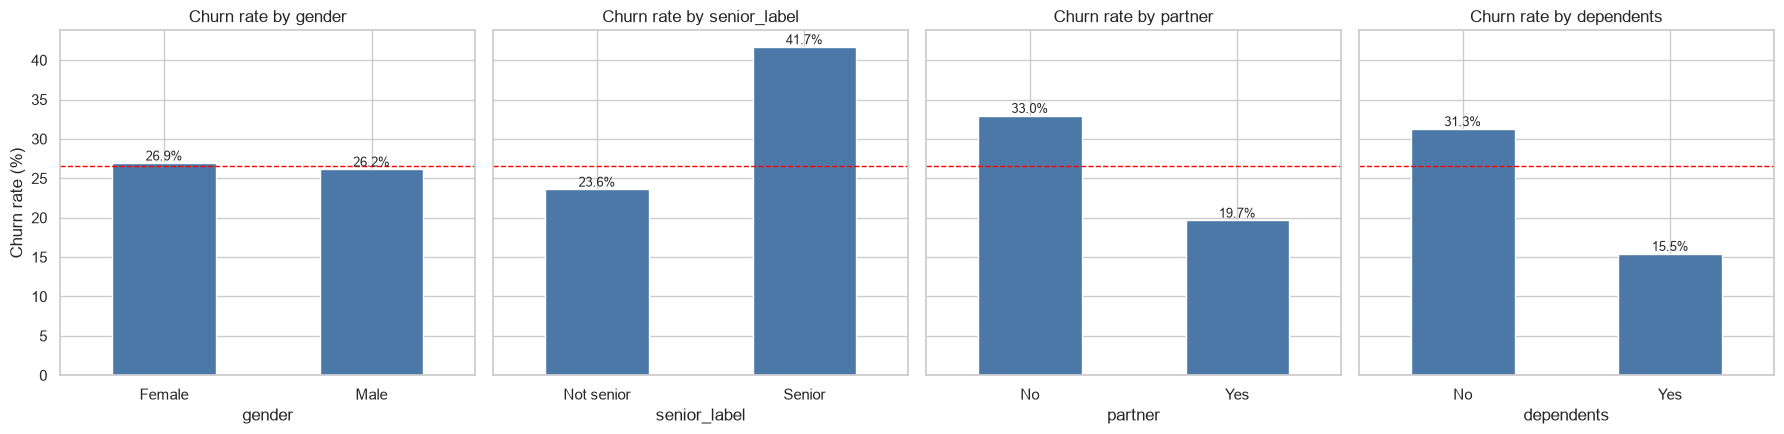

In [43]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharey=True)
for ax, col in zip(axes, ["gender", "senior_label", "partner", "dependents"]):
    rate = df_clean.groupby(col)["churn"].mean() * 100
    rate.plot(kind="bar", ax=ax, color="#4C78A8", rot=0)
    ax.axhline(df_clean["churn"].mean() * 100, color="red", linestyle="--", linewidth=1)
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate (%)")
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width()/2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

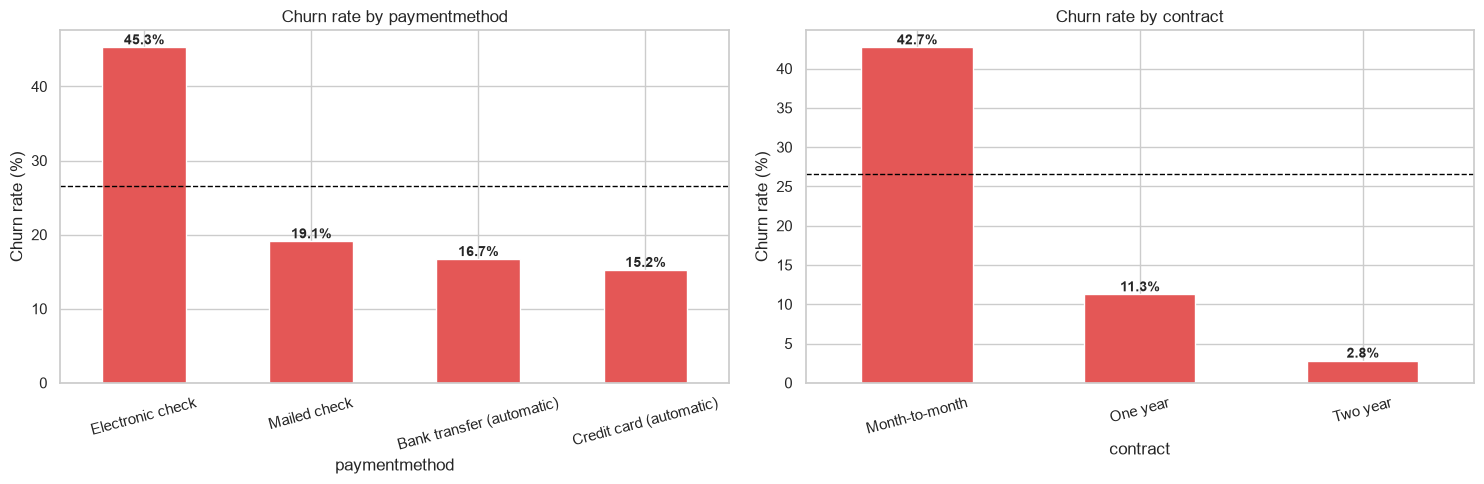

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, col in zip(axes, ["paymentmethod", "contract"]):
    rate = (df_clean.groupby(col)["churn"].mean() * 100).sort_values(ascending=False)
    rate.plot(kind="bar", ax=ax, color="#E45756", rot=15)
    ax.axhline(df_clean["churn"].mean() * 100, color="black", linestyle="--", linewidth=1)
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate (%)")
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width()/2, p.get_height()),
                    ha="center", va="bottom", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()

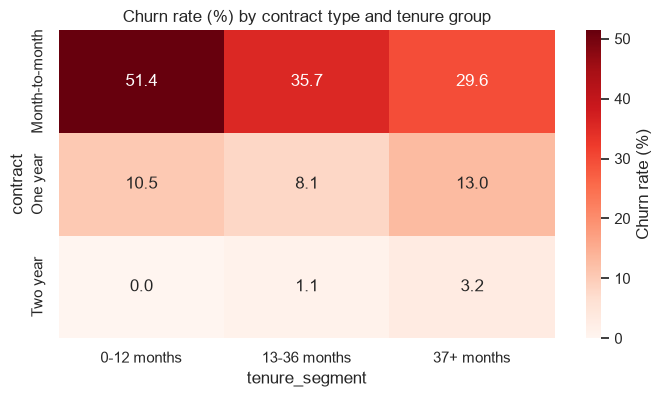

In [45]:
pivot = (df_clean.pivot_table(index="contract", columns="tenure_segment",
                              values="churn", aggfunc="mean", observed=True) * 100).round(1)
plt.figure(figsize=(8, 4))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Churn rate (%)"})
plt.title("Churn rate (%) by contract type and tenure group")
plt.show()

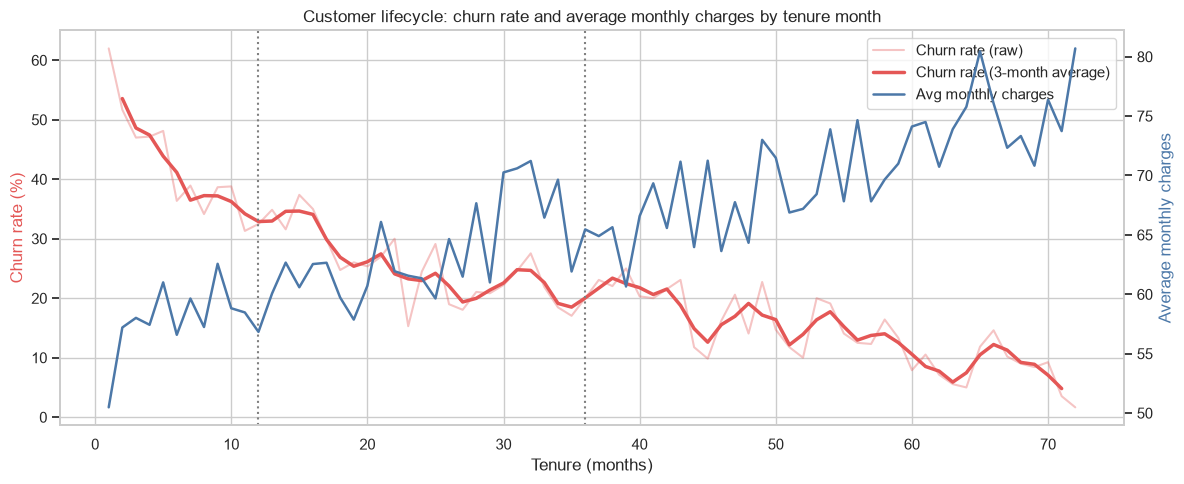

In [46]:
monthly = df_clean[df_clean["tenure"] > 0].groupby("tenure").agg(
    churn_rate=("churn", lambda s: s.mean() * 100),
    customers=("churn", "size"),
    avg_monthly=("monthlycharges", "mean"),
)
monthly["churn_smooth"] = monthly["churn_rate"].rolling(3, center=True).mean()

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(monthly.index, monthly["churn_rate"], alpha=0.35, color="#E45756", label="Churn rate (raw)")
ax1.plot(monthly.index, monthly["churn_smooth"], color="#E45756", linewidth=2.5, label="Churn rate (3-month average)")
ax1.set_xlabel("Tenure (months)")
ax1.set_ylabel("Churn rate (%)", color="#E45756")
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["avg_monthly"], color="#4C78A8", linewidth=1.8, label="Avg monthly charges")
ax2.set_ylabel("Average monthly charges", color="#4C78A8")
ax2.grid(False)
for stage_end in [12, 36]:
    ax1.axvline(stage_end, color="grey", linestyle=":")
ax1.set_title("Customer lifecycle: churn rate and average monthly charges by tenure month")
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right")
plt.tight_layout()
plt.show()

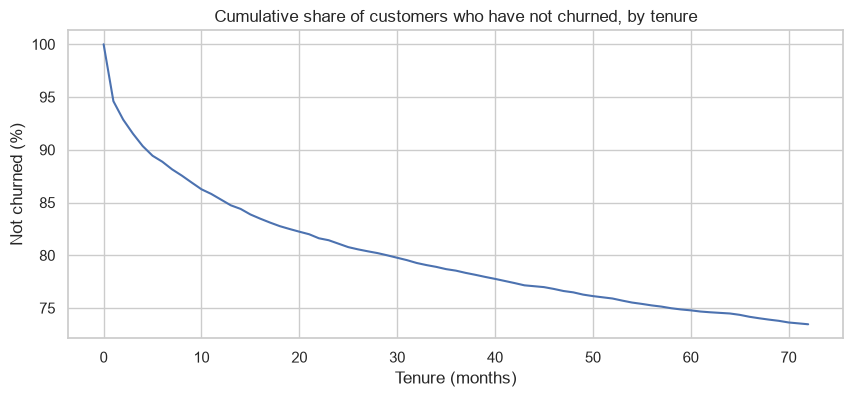

In [47]:
surv = df_clean.groupby("tenure")["churn"].agg(["size", "sum"])
surv["retained_pct"] = 100 - (surv["sum"].cumsum() / surv["size"].sum() * 100)
plt.figure(figsize=(10, 4))
plt.plot(surv.index, surv["retained_pct"])
plt.title("Cumulative share of customers who have not churned, by tenure")
plt.xlabel("Tenure (months)"); plt.ylabel("Not churned (%)")
plt.show()

In [49]:
from scipy.stats import chi2_contingency
for col in ["gender", "senior_label", "paymentmethod", "contract"]:
    chi2, p, _, _ = chi2_contingency(pd.crosstab(df_clean[col], df_clean["churn"]))
    print(f"{col:15s} p-value = {p:.4g}  ->", "significant" if p < 0.05 else "not significant")

gender          p-value = 0.4866  -> not significant
senior_label    p-value = 1.51e-36  -> significant
paymentmethod   p-value = 3.682e-140  -> significant
contract        p-value = 5.863e-258  -> significant
